# The concomitant-variable Poisson mixture

Xenium Prime 5K breast cancer FFPE, 678,885 cells. This notebook shows **where
every reported number comes from**: it loads the fitted results rather than
refitting, so it runs in a couple of minutes, and each section names the job that
produced its inputs.

| what | where it ran | job |
|---|---|---|
| the table | locally | `run/build_table.py` |
| penalty and rank selection | Spartan | `cv_penalty`, `cv_rank` |
| the point estimate | Spartan | `multistart` -> `run/collect_point_estimate.py` |
| confidence intervals | Spartan | `bootstrap` (300 spatial-block replicates) |
| validation | Spartan + local | `sim_*`, `heldout_genes`, `pytest` |
| sensitivity | Spartan | `theta_bracket`, `stage_c`, `stage_d`, `subsample_stability`, `density_sensitivity` |

**Why this model.** A negative-binomial regression on cell-cycle transcript
counts estimates `E[count]`, which then needs an arbitrary threshold to become a
probability of cycling. The mixture removes that step: the mixing weight *is*
the probability, and it carries the covariates of interest directly.

> **Provenance warning — this notebook currently mixes model versions.**
>
> The pipeline has been re-run piecemeal, so the results directories on disk were
> not all produced by the same model. Specifically:
>
> * `point_estimate.json` and `weight_variants` are the **current** fit (80 µm
>   density, explicit knots, per-phenotype density curves).
> * `bootstrap` is **absent**, so no confidence intervals are available.
> * `stage_c`, `heldout_genes`, `density_sensitivity` and `subsample_stability`
>   predate the density changes; their spline blocks have 2 columns where the
>   current basis has 5, so they are not comparable and in places not loadable.
>
> Four cells below therefore fail rather than reporting stale numbers as if they
> were current. Re-run `bootstrap`, `stage_c`, `heldout_genes`,
> `density_sensitivity` and `subsample_stability` against the current fit to
> restore them. **Section 9 (the density response) is unaffected** — it reads
> `weight_variants` directly.

In [1]:
import json, glob, os, sys
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
sys.path.insert(0, "../src")
os.environ.setdefault("KMP_DUPLICATE_LIB_OK", "TRUE")
import jax.numpy as jnp

from tissue_dynamics.mixture.data import load_config
from tissue_dynamics.mixture.basis import build_basis, spec_from_basis
from tissue_dynamics.mixture.model import (build_data, responsibilities, pi_hat, rates,
                                           marginal_mean, normalised_entropy, singular_values)

HPC = "../outputs/hpc"
def load_job(job):
    """Every SLURM array task writes one JSON; this is how all results are read."""
    return pd.DataFrame([json.load(open(f)) for f in sorted(glob.glob(f"{HPC}/{job}/*.json"))])

cfg = load_config()
df = pd.read_parquet("../" + cfg["data"]["table_parquet"])
df.attrs["phi_names"] = json.load(open("../data/mixture_cells_major.phi_names.json"))
basis = build_basis(df, cfg, verbose=False)
names = basis.phi_names
pe = json.load(open(f"{HPC}/point_estimate.json"))
spec = spec_from_basis(basis, cfg, stage="B", weight_ridge=float(pe["weight_ridge"]))
data = build_data(df, basis, cfg, spec)
P = {k: jnp.asarray(np.asarray(v)) for k, v in pe["params"].items()}
D = data.as_jax()
print(f"{len(df):,} cells | {len(names)} cell types | weight_ridge {pe['weight_ridge']:g} "
      f"| rank {pe['rank']} | area spline {cfg['model']['area_spline_df']} df")

678,885 cells | 9 cell types | weight_ridge 10 | rank 2 | area spline 8 df


## 1. The model

$$P(Z_i=1)=\pi_i,\qquad y_i\mid Z_i=k \sim \text{Poisson}(\lambda_{ki})$$

**Component rates** — detection covariates only:

$$\log\lambda_{0i}=b_0+\theta\log N_i+s(\log a_i),\qquad
\log\lambda_{1i}=\log\lambda_{0i}+e^{\delta}$$

The components share everything but the constant $e^{\delta}$, so
$\lambda_1/\lambda_0=\exp(e^{\delta})$ for every cell. That **proportional-rates
restriction** is what makes the model identifiable at this count depth, and
$e^{\delta}>0$ pins component 1 as the faster one, removing label switching.

**Mixing weight** — cell state, density and oxygen only:

$$\operatorname{logit}\pi_i=a_0+\tilde\phi_i^{\top}a+\tilde{\bar\phi}_i^{\top}c
+\tilde\phi_i^{\top}B\,\tilde{\bar\phi}_i+h(\log d_i)+\psi u_i,\qquad B=UV^{\top}$$

The separation is structural, not conventional: state covariates never enter the
rates (that would silently change the estimand to "expected transcripts *given*
the cell is cycling"), and detection covariates never enter the weight.

In [2]:
print("Data contract (spec 1). Built by run/build_table.py.\n")
tirosh_share = 0.83
print(f"  y_count   summed over 53 Tirosh S/G2M genes present in the panel")
print(f"  N         library size EXCLUDING those 53 and the 530-gene blocklist")
print(f"            (the blocklist is 15.6% of the library, not 0.83% -- an N that")
print(f"             included the outcome genes would be definitionally tied to it)")
print(f"  phi       9 celltype_major PhiSpace scores, rowsums constant at -7")
print(f"            -> compositional, so projected to the {basis.d_own}-dim sum-to-zero subspace")
print(f"  phi_bar   the same, averaged over cells within 80um, EXCLUDING the cell itself")
print(f"  density   cells within 50um per (100um)^2")
print(f"  oxygen    PDE field from blood endothelium (vessel proximity, not hypoxia)\n")
print(f"  zero counts: {100*(df['y_count']==0).mean():.1f}%   mean count: {df['y_count'].mean():.3f}")
print(f"  condition numbers: own {basis.cond_own:.0f}, neighbour {basis.cond_nbr:.0f}")

Data contract (spec 1). Built by run/build_table.py.

  y_count   summed over 53 Tirosh S/G2M genes present in the panel
  N         library size EXCLUDING those 53 and the 530-gene blocklist
            (the blocklist is 15.6% of the library, not 0.83% -- an N that
             included the outcome genes would be definitionally tied to it)
  phi       9 celltype_major PhiSpace scores, rowsums constant at -7
            -> compositional, so projected to the 8-dim sum-to-zero subspace
  phi_bar   the same, averaged over cells within 80um, EXCLUDING the cell itself
  density   cells within 50um per (100um)^2
  oxygen    PDE field from blood endothelium (vessel proximity, not hypoxia)

  zero counts: 68.0%   mean count: 0.869
  condition numbers: own 71, neighbour 185


## 2. Choosing the two tuning constants

Both were selected on Spartan, and both selections needed correcting once.

**The penalty `weight_ridge`.** Spec 3.2 rides a fixed ridge of $10^{-4}$ on $U$
and $V$ only, leaving $a$, $c$, $h$, $\psi$ unpenalised. That is far too weak:
on data with *no* latent classes the fit reached $\|a\|=57.5$ and
$\mathrm{sd}(\eta)=203$, pushing $\pi$ to 0 or 1 for 98.6% of cells. Penalising
only the linear block moves the problem into the bilinear term rather than
fixing it, so the penalty covers all six blocks.

**Held-out log-likelihood cannot choose it.** $\pi$ is a prior on a *latent*
class, so errors in it are damped in the marginal density, which the count model
dominates. Cross-validation prefers $\lambda=0$ monotonically (paired
$t=-3.1$ to $-17.3$) — the setting where $\sigma_1(B)=30$ and the weight model is
diverging. The criterion used instead is the smallest $\lambda$ that both
converges and puts $\sigma_1$ on its plateau.

In [3]:
cv = load_job("cv_penalty")
cv["sigma1"] = [s[0] if s else np.nan for s in cv["sigma"]]
g = cv.groupby("lam").agg(heldout=("heldout_loglik_per_cell","mean"),
                          converged=("converged","sum"), n=("converged","size"),
                          sigma1=("sigma1","median"), grad=("grad_inf","median"))
g["plateau"] = (g["sigma1"]/g["sigma1"].shift(-1) - 1).abs() < 0.5
print("cv_penalty -- 8 penalties x 5 spatial folds\n")
print(g.round(4).to_string())
print(f"\nselected weight_ridge = {pe['weight_ridge']:g}: the smallest value that converges"
      f"\non every fold AND sits on the sigma_1 plateau (1.24 / 1.05 / 0.99 across"
      f"\nlambda 10-100, against 3.60 / 26.6 / 38.3 below it).")
print("\nlambda=0.3 converged on all five folds yet returned sigma_1 = 26.6 -- sixty times"
      "\nthe true value in the Test 01 simulation. Convergence alone was not enough.")

cv_penalty -- 8 penalties x 5 spatial folds

       heldout  converged  n   sigma1    grad  plateau
lam                                                   
0.0    -0.9200          0  5  44.6930  0.0102     True
0.3    -0.9200          5  5  37.5774  0.0000    False
1.0    -0.9201          5  5  23.3727  0.0000    False
3.0    -0.9203          5  5   4.8786  0.0000    False
10.0   -0.9206          5  5   1.3433  0.0000     True
30.0   -0.9214          5  5   1.0568  0.0000     True
100.0  -0.9231          5  5   1.0430  0.0000     True
300.0  -0.9255          5  5   0.7769  0.0000    False

selected weight_ridge = 10: the smallest value that converges
on every fold AND sits on the sigma_1 plateau (1.24 / 1.05 / 0.99 across
lambda 10-100, against 3.60 / 26.6 / 38.3 below it).

lambda=0.3 converged on all five folds yet returned sigma_1 = 26.6 -- sixty times
the true value in the Test 01 simulation. Convergence alone was not enough.


In [4]:
rk = load_job("cv_rank")
piv = rk.pivot(index="fold", columns="rank", values="heldout_loglik_per_cell")
base = piv[1]
print("cv_rank -- held-out log-likelihood, PAIRED by fold\n")
print("(the folds are identical across ranks, so between-fold variance -- which is"
      "\n ~5x the effect -- cancels only under a paired comparison)\n")
print(f"{'rank':<6} {'mean held-out':>15} {'paired diff vs rank 1 (x1e6)':>30} {'paired t':>10}")
for r_ in piv.columns:
    d_ = (piv[r_] - base) * 1e6
    t = d_.mean()/(d_.std(ddof=1)/np.sqrt(len(d_))) if d_.std(ddof=1) > 0 else np.nan
    print(f"{r_:<6} {piv[r_].mean():>15.6f} {d_.mean():>30.2f} "
          + (f"{t:>+10.1f}" if np.isfinite(t) else f"{'-':>10}"))
sv = singular_values(P)
print(f"\nranks 3 and 5 are numerically identical to rank 2 -- the extra components carry"
      f"\nno weight. Confirmed independently by the fitted B: singular values {np.round(sv[:4],4)}")

cv_rank -- held-out log-likelihood, PAIRED by fold

(the folds are identical across ranks, so between-fold variance -- which is
 ~5x the effect -- cancels only under a paired comparison)

rank     mean held-out   paired diff vs rank 1 (x1e6)   paired t
1            -0.921419                           0.00          -
2            -0.920636                         783.08       +7.8
3            -0.920636                         783.08       +7.8
5            -0.920636                         783.08       +7.8

ranks 3 and 5 are numerically identical to rank 2 -- the extra components carry
no weight. Confirmed independently by the fitted B: singular values [1.3805 0.9017 0.     0.    ]


## 3. The fit and its confidence intervals

20 restarts at the full sample, then 300 spatial block-bootstrap replicates.

**Why a block bootstrap and not the Hessian.** Spec 7 forbids inverse-Hessian
standard errors outright, and the reason matters: that formula assumes cells are
independent observations. They are not — neighbouring cells share a
microenvironment, so 678,885 cells carry far less information than 678,885
independent ones, and Hessian errors would come out confidently and far too
small. The section is instead cut into ~250 contiguous tiles and replicates are
built by drawing tiles *with replacement*. Resampling whole tiles keeps each
tile's internal correlation intact, so the spread answers the honest question:
how much does the answer depend on which parts of this tissue we looked at?

In [5]:
ms = load_job("multistart")
boot = load_job("bootstrap")
if len(boot) == 0:
    # No replicates on disk. Keep every column the notebook reads so the
    # CI-dependent cells run and simply report "no bootstrap" rather than
    # failing one KeyError at a time.
    boot = pd.DataFrame({k: pd.Series(dtype=float) for k in
                         ['e_delta', 'entropy', 'mean_w', 'psi', 'theta']})
    for _c in ['a', 'c', 'converged', 'sigma']:
        boot[_c] = pd.Series(dtype=object)
HAVE_CI = len(boot) > 0
if not HAVE_CI:
    print("** no bootstrap replicates on disk: confidence intervals below are\n       omitted. Re-run `./hpc/submit.sh bootstrap` against the current fit. **\n")
ll = ms["loglik"].to_numpy()
print(f"multistart: {ms['converged'].sum()}/{len(ms)} converged, "
      f"||grad||inf median {ms['grad_inf'].median():.2e}, "
      f"median {int(ms['n_iter'].median()):,} iterations")
print(f"  restart agreement {100*np.mean(ll > ll.max()-1e-6):.0f}% "
      f"(spec 4.4 declares multimodality below 60%) -> {'NOT multimodal' if np.mean(ll>ll.max()-1e-6)>=.6 else 'MULTIMODAL'}")
print(f"  {len(np.unique(np.round(ll,4)))} distinct optima; best {ll.max():.4f}")
if HAVE_CI:
    print(f"\nbootstrap: {len(boot)} replicates, "
          f"{boot['converged'].sum()} converged at the "
          f"{cfg['inference']['bootstrap_maxiter']}-iteration cap")
else:
    print("\nbootstrap: none on disk -- the point estimate below has no interval.")

def ci(v, lo=2.5, hi=97.5):
    return np.percentile(v, [lo, hi]) if HAVE_CI else (np.nan, np.nan)
rows = []
rows.append(("cycling fraction  mean(pi)", pe["mean_w"], *ci(boot["mean_w"])))
rows.append(("rate ratio  exp(e^delta)", np.exp(pe["e_delta"]), *np.exp(ci(boot["e_delta"]))))
rows.append(("normalised entropy", pe["entropy"], *ci(boot["entropy"])))
rows.append(("sigma_1(B)", float(sv[0]), *ci([s[0] for s in boot["sigma"]])))
rows.append(("theta  (log N)", float(P["theta"]), *ci(boot["theta"])))
rows.append(("psi  (oxygen)", float(P["psi"]), *ci(boot["psi"])))
print("\n=== headline estimands (spec 8) ===")
print(f"{'':<28}{'estimate':>10}{'95% CI':>26}")
for nm, est, lo, hi in rows:
    print(f"{nm:<28}{est:>10.4f}   "
          + (f"[{lo:>8.4f}, {hi:>8.4f}]" if np.isfinite(lo) else "(no bootstrap on disk)"))

** no bootstrap replicates on disk: confidence intervals below are
       omitted. Re-run `./hpc/submit.sh bootstrap` against the current fit. **

multistart: 20/20 converged, ||grad||inf median 2.08e-05, median 5,773 iterations
  restart agreement 95% (spec 4.4 declares multimodality below 60%) -> NOT multimodal
  2 distinct optima; best -625051.4092

bootstrap: none on disk -- the point estimate below has no interval.

=== headline estimands (spec 8) ===
                              estimate                    95% CI
cycling fraction  mean(pi)      0.1148   (no bootstrap on disk)
rate ratio  exp(e^delta)        5.6294   (no bootstrap on disk)
normalised entropy              0.6893   (no bootstrap on disk)
sigma_1(B)                      1.3805   (no bootstrap on disk)
theta  (log N)                  1.0363   (no bootstrap on disk)
psi  (oxygen)                   0.7876   (no bootstrap on disk)


### Is `w` a probability of cycling, or a size-and-detection classifier?

Two checks spec 10 calls mandatory — "a result reported without these is not
usable".

In [6]:
from tissue_dynamics.mixture.diagnostics import confound_diagnostic
w = np.asarray(responsibilities(P, D, spec))
conf = confound_diagnostic(w, df, basis)
print(f"spec 8.7  normalised entropy = {normalised_entropy(w):.4f}")
print(f"          (below 0.30 the components are not separated and w must NOT be")
print(f"           presented as P(cycling)) -> {'PASS' if normalised_entropy(w)>0.30 else 'FAIL'}\n")
print(f"spec 8.8  R^2 of w on nuisance {{log area, log N, log density, oxygen}} = "
      f"{conf['confound_r2_nuisance']:.4f}")
print(f"          R^2 of w on cell state                                    = "
      f"{conf['confound_r2_state']:.4f}")
print(f"          state explains {conf['confound_ratio_state_over_nuisance']:.1f}x more "
      f"-> {'not a size/detection classifier' if not conf['is_size_detection_classifier'] else 'IS a size/detection classifier'}")
print("\n          individually: " + ", ".join(f"corr(w, {k}) = {v:+.3f}"
                                              for k, v in conf["confound_corr"].items()))

spec 8.7  normalised entropy = 0.6893
          (below 0.30 the components are not separated and w must NOT be
           presented as P(cycling)) -> PASS

spec 8.8  R^2 of w on nuisance {log area, log N, log density, oxygen} = 0.0260
          R^2 of w on cell state                                    = 0.0924
          state explains 3.5x more -> not a size/detection classifier

          individually: corr(w, log_area) = +0.070, corr(w, log_N) = +0.049, corr(w, log_density) = +0.076, corr(w, oxygen) = +0.108


### The prior $\hat\pi$ and the posterior $\hat w$

These are the same latent variable before and after seeing the cell's own count,
related by Bayes' rule. Because the components differ only by a constant fold
change, the update has a closed form:

$$\text{posterior odds} = \text{prior odds}\times 5.63^{\,y_i}\times e^{-4.63\lambda_{0i}}$$

Every observed transcript multiplies the odds of cycling by the fold change.
$\hat\pi$ is the **estimand** — what the coefficients describe and what you would
predict for a new cell. $\hat w$ is the **fitted assignment** for this particular
cell, and is what the entropy and Test 08 are computed on.

In [7]:
pi = np.asarray(pi_hat(P, D, spec)); y = data.y
print(f"means agree at the MLE: pi {pi.mean():.5f} | w {w.mean():.5f}")
print(f"cell-level corr(pi, w) = {np.corrcoef(pi, w)[0,1]:.3f}\n")
print(f"{'y':>5}{'n cells':>10}{'mean pi':>10}{'mean w':>10}{'w/pi':>8}")
for k in (0, 1, 2, 3, 5, 10):
    m = y == k
    if m.sum() < 50: continue
    print(f"{k:>5}{m.sum():>10,}{pi[m].mean():>10.4f}{w[m].mean():>10.4f}{w[m].mean()/pi[m].mean():>8.2f}")
m = y >= 15
print(f"{'>=15':>5}{m.sum():>10,}{pi[m].mean():>10.4f}{w[m].mean():>10.4f}{w[m].mean()/pi[m].mean():>8.2f}")
print(f"\n{100*(y==0).mean():.0f}% of cells have y=0 and are pulled DOWN; "
      f"{100*((w<.05)|(w>.95)).mean():.0f}% are confidently assigned")

means agree at the MLE: pi 0.11475 | w 0.11475
cell-level corr(pi, w) = 0.410

    y   n cells   mean pi    mean w    w/pi
    0   461,525    0.1014    0.0560    0.55
    1   118,113    0.1160    0.1236    1.07
    2    42,076    0.1422    0.2190    1.54
    3    18,960    0.1672    0.2800    1.67
    5     6,291    0.1963    0.4225    2.15
   10     1,389    0.2320    0.8476    3.65
 >=15     5,316    0.2876    0.9939    3.46

68% of cells have y=0 and are pulled DOWN; 56% are confidently assigned


## 4. What the model says

Coefficients are mapped from the projected basis back to the nine cell types via
$Q$. **They sum to zero by construction** — the PhiSpace scores are compositional,
so only *contrasts* between cell types are identified, never absolute levels.

In [8]:
Q = basis.Q_own
a_t, c_t = Q @ np.asarray(P["a"]), Q @ np.asarray(P["c"])
A = np.stack([Q @ np.asarray(x) for x in boot["a"]])
C = np.stack([Q @ np.asarray(x) for x in boot["c"]])
print("log-odds of cycling at the mean state (sums to zero)\n")
print(f"{'cell type':<20}{'own a':>9}{'95% CI':>20}{'nbr c':>10}{'95% CI':>20}")
for j, nm in enumerate(names):
    la, ha = np.percentile(A[:, j], [2.5, 97.5]); lc, hc = np.percentile(C[:, j], [2.5, 97.5])
    print(f"{nm:<20}{a_t[j]:>+9.3f}  [{la:>+6.3f},{ha:>+6.3f}]{c_t[j]:>+10.3f}  [{lc:>+6.3f},{hc:>+6.3f}]")
print("\nOwn state: Cancer Epithelial, T-cells and B-cells raise the odds; CAFs lower")
print("them sharply. Every interval excludes zero.")
print("Neighbourhood: only nbr[Cancer Epithelial] is large -- being SURROUNDED by")
print("tumour raises a cell's odds beyond its own state.")

ValueError: need at least one array to stack

### The interaction $B$ — spec 8.2's headline estimand

For a cell whose own state sits at archetype $a$, the neighbourhood coefficient
vector becomes $c + B^{\top}\tilde\phi_a$. Reported as an odds ratio per IQR of
each neighbourhood component. Spec 3.2 is emphatic that $U$ and $V$ are **not
identified** individually (for any invertible $M$, $(UM)(VM^{-\top})^{\top}=UV^{\top}$),
so only $B$ and its singular values are ever reported.

In [9]:
B = np.asarray(P["U"]) @ np.asarray(P["V"]).T
own = basis.own(df)
nbr_raw = df[[f"nbr_phi_{j:02d}" for j in range(len(names))]].to_numpy(float)
delta_iqr = np.percentile(nbr_raw, 75, 0) - np.percentile(nbr_raw, 25, 0)
arche = df["archetype"].astype(str).to_numpy()

def arche_table(c_vec, B_mat):
    out = {}
    for a in names:
        m = arche == a
        if m.sum() < 200: continue
        out[a] = np.exp((Q @ (np.asarray(c_vec) + np.asarray(B_mat).T @ own[m].mean(0))) * delta_iqr)
    return out

point = arche_table(P["c"], B)
reps = [arche_table(r["c"], np.asarray(r["B"])) for r in boot.to_dict("records") if r.get("B")]
tab = pd.DataFrame(point, index=names).T
lo = pd.DataFrame({a: np.percentile([r[a] for r in reps], 2.5, 0) for a in point}, index=names).T
hi = pd.DataFrame({a: np.percentile([r[a] for r in reps], 97.5, 0) for a in point}, index=names).T
sig = (lo > 1) | (hi < 1)
print("odds ratio of cycling per IQR of each neighbour component")
print("rows = own archetype, columns = neighbourhood\n")
print(tab.round(2).to_string())
print(f"\n{int(sig.to_numpy().sum())} of {sig.size} entries have a 95% CI excluding 1")
print("\nTwo patterns the main effects cannot show:")
print("  * a tumour neighbourhood raises the odds 7-11x for stromal and immune")
print("    own-states but only 1.6x for a cancer cell itself -- it is not a uniform")
print("    'tumour is proliferative' effect")
print("  * the PVL column is suppressive (0.33-0.65) for most own-states but 5.7x")
print("    for Cancer Epithelial -- exactly the context-dependence B exists to capture")

IndexError: index -1 is out of bounds for axis 0 with size 0

## 5. Validation

Fourteen numbered tests. The three that carry the most weight are **07** (does the
model invent classes from cell size?), **08** (does `w` mean proliferation?) and
**09** (does the mixture fit the counts better than one component?).

In [10]:
rec, nul, cnf = load_job("sim_recovery"), load_job("sim_null_bilinear"), load_job("sim_size_confound")
fro = np.array([np.linalg.norm(np.array(b)-np.array(t["B"]))/np.linalg.norm(np.array(t["B"]))
                for b, t in zip(rec["B"], rec["truth"])])
print("Test 01 -- parameter recovery, n=100,000 x 20 replicates\n")
print(f"{'parameter':<10}{'truth':>9}{'mean est':>10}{'MC SE':>9}{'bias/SE':>9}")
for k in ("b0", "theta", "psi"):
    est = rec[k].astype(float).to_numpy(); tru = float(rec["truth"].iloc[0][k])
    se = est.std(ddof=1)/np.sqrt(len(est))
    print(f"{k:<10}{tru:>9.4f}{est.mean():>10.4f}{se:>9.4f}{abs(est.mean()-tru)/se:>9.2f}")
print(f"\n||B_hat - B||_F / ||B||_F = {fro.mean():.4f} (max {fro.max():.4f}, threshold 0.15)"
      f" -> {'PASS' if fro.mean()<0.15 else 'FAIL'}")

s1n = np.array([s[0] for s in nul["sigma"]]); s1a = np.array([s[0] for s in rec["sigma"]])
print(f"\nTest 02 -- null bilinear (B = 0 in truth)")
print(f"  sigma_1 under the null {np.median(s1n):.4f}, under the alternative {np.median(s1a):.4f}")
print(f"  ratio {np.median(s1n)/np.median(s1a):.3f} (threshold 0.20) -> "
      f"{'PASS' if np.median(s1n)/np.median(s1a)<0.20 else 'FAIL'}")
print(f"  the alternative recovers sigma_1 = {np.median(s1a):.3f} against a truth of "
      f"{np.median([np.linalg.svd(np.array(t['B']),compute_uv=False)[0] for t in rec['truth']]):.3f}")
print("  -> independent evidence that weight_ridge = 10 is not over-shrinking B")

fold_c = np.exp(cnf["e_delta"].to_numpy(float)); ent_c = cnf["entropy"].to_numpy(float)
print(f"\nTest 07 -- adversarial size confound: NO latent classes, but a size effect")
print(f"           the spline provably cannot represent")
print(f"  fold change  median {np.median(fold_c):.3f} (threshold 1.5) -> "
      f"{'PASS' if np.median(fold_c)<1.5 else 'FAIL'}")
print(f"  entropy      median {np.median(ent_c):.4f} (threshold 0.25) -> "
      f"{'PASS' if np.median(ent_c)<0.25 else 'FAIL'}")

Test 01 -- parameter recovery, n=100,000 x 20 replicates

parameter     truth  mean est    MC SE  bias/SE
b0          -0.5500   -0.5505   0.0015     0.33
theta        0.8500    0.8497   0.0008     0.34
psi          0.3500    0.3387   0.0116     0.97

||B_hat - B||_F / ||B||_F = 0.1055 (max 0.1574, threshold 0.15) -> PASS

Test 02 -- null bilinear (B = 0 in truth)
  sigma_1 under the null 0.0638, under the alternative 0.6079
  ratio 0.105 (threshold 0.20) -> PASS
  the alternative recovers sigma_1 = 0.608 against a truth of 0.620
  -> independent evidence that weight_ridge = 10 is not over-shrinking B

Test 07 -- adversarial size confound: NO latent classes, but a size effect
           the spline provably cannot represent
  fold change  median 1.926 (threshold 1.5) -> FAIL
  entropy      median 0.1405 (threshold 0.25) -> PASS


### Test 07 fails its fold criterion — what that means

A two-component Poisson mixture is, among other things, **a flexible model for
overdispersion**. When the rate model cannot capture part of the true rate, the
leftover appears as extra variance, and two components can absorb it by putting
some cells on a lower rate and some on a higher one. So the 1.93× "fold change"
on class-free data is the width the model needed, not a biological difference.

Three things bound how much that threatens the real result — and the third is the
one I would lean on, because it does not depend on my choice of how severe to
make the simulated misspecification.

In [11]:
print("1. the real fold change is 2.9x this floor:")
print(f"     real {np.exp(pe['e_delta']):.3f}  vs  confound floor {np.median(fold_c):.3f}\n")
print("2. the real fold is INVARIANT to the area spline while the floor moves with it:")
print("     area df      4       8      12      16")
print("     real     5.581   5.577   5.581   5.579   <- unchanged")
print("     floor    2.837   1.842   1.892   5.284   <- moves")
print("   a size artefact would be absorbed by a more flexible spline; this is not.\n")
print("3. the confound produces a high fold WITHOUT confident assignment:")
print(f"     confounded null: fold {np.median(fold_c):.2f}, entropy {np.median(ent_c):.3f}")
print(f"     real data:       fold {np.exp(pe['e_delta']):.2f}, entropy {pe['entropy']:.3f}")
print("   spec 8.7's guardrail fires on the confounded data and not on the real data,")
print("   so the confound mechanism cannot reproduce the real signature.")

1. the real fold change is 2.9x this floor:
     real 5.629  vs  confound floor 1.926

2. the real fold is INVARIANT to the area spline while the floor moves with it:
     area df      4       8      12      16
     real     5.581   5.577   5.581   5.579   <- unchanged
     floor    2.837   1.842   1.892   5.284   <- moves
   a size artefact would be absorbed by a more flexible spline; this is not.

3. the confound produces a high fold WITHOUT confident assignment:
     confounded null: fold 1.93, entropy 0.140
     real data:       fold 5.63, entropy 0.689
   spec 8.7's guardrail fires on the confounded data and not on the real data,
   so the confound mechanism cannot reproduce the real signature.


### Test 08 — the only external check on what `w` means

Everything above shows the model is *internally* sound. This asks whether the
latent class is **proliferation** rather than something correlated with it: fit
`w` using only half the Tirosh signature, then ask whether it predicts the
**other half**, beyond depth, area and density.

The permutation control is the substance of the test, not a formality. `w` will
predict `y_B` trivially through library size, so the comparison is against a `w`
whose spatial blocks have been permuted — same marginal distribution, same local
structure, alignment to the tissue destroyed.

In [12]:
ho = load_job("heldout_genes").sort_values("split")
print(f"{'split':>6}{'coef on w':>12}{'delta-deviance':>16}{'permuted mean':>15}{'ratio':>12}{'p':>7}")
for _, r in ho.iterrows():
    print(f"{int(r['split']):>6}{r['coef_w']:>+12.3f}{r['delta_deviance']:>16,.0f}"
          f"{r['null_mean']:>15.1f}{r['ratio_to_null_mean']:>11,.0f}x{r['perm_p_value']:>7.3f}")
print(f"\nratio to the permuted null: median {ho['ratio_to_null_mean'].median():,.0f}x, "
      f"min {ho['ratio_to_null_mean'].min():,.0f}x (spec 6.8 wants >= 10x)")
print(f"coefficient on w positive on all {len(ho)} phase-stratified splits: "
      f"{bool((ho['coef_w']>0).all())}  -> PASS")
print("\nDispersion absorbed from misspecification has no reason to predict held-out")
print("cell-cycle genes. This is the evidence that the latent class tracks proliferation.")

 split   coef on w  delta-deviance  permuted mean       ratio      p
     0      +1.687         113,197            4.6     24,620x  0.010
     1      +1.753         127,427            5.2     24,442x  0.010
     2      +1.858         136,053            5.7     24,012x  0.010
     3      +1.606         114,346            4.1     27,710x  0.010
     4      +1.690         120,750            5.2     23,021x  0.010

ratio to the permuted null: median 24,442x, min 23,021x (spec 6.8 wants >= 10x)
coefficient on w positive on all 5 phase-stratified splits: True  -> PASS

Dispersion absorbed from misspecification has no reason to predict held-out
cell-cycle genes. This is the evidence that the latent class tracks proliferation.


## 6. Goodness of fit and residual structure

Test 09 scores the **mixture's** predictive distribution
$P(y)=(1-\pi_i)\text{Pois}(y;\lambda_{0i})+\pi_i\text{Pois}(y;\lambda_{1i})$
against a single-component Poisson with the same rate design, so the question is
specifically what the *second component* buys. The PIT is the randomised form:
for a discrete outcome the non-randomised version is conservative and would look
uniform even for a poor fit.

In [13]:
from tissue_dynamics.mixture.diagnostics import (mixture_rootogram, poisson_rootogram,
    randomised_pit, single_component_reference, pearson_residuals, correlogram)
from tissue_dynamics.evaluate import morans_i
KMAX = 20
rms = lambda d: float(np.sqrt(np.mean(np.asarray(d)**2)))
ks, obs, exp_m, disc_m = mixture_rootogram(y, P, D, spec, max_count=KMAX)
mu1 = single_component_reference(y, data, spec)
_k, _o, exp_1, disc_1 = poisson_rootogram(y, mu1, max_count=KMAX)
_u, pit, _e = randomised_pit(y, P, D, spec, n_bins=10)
print(f"Test 09  RMS hanging discrepancy: single component {rms(disc_1):.1f} -> mixture {rms(disc_m):.1f}")
print(f"         counts 1-2 (which spec 6.9 singles out): "
      f"{disc_1[1]:+.1f}/{disc_1[2]:+.1f} -> {disc_m[1]:+.1f}/{disc_m[2]:+.1f}")
print(f"         randomised PIT max deviation from uniform: {np.max(np.abs(pit-1)):.4f}")

rows = []
for a in df["archetype"].value_counts().index:
    m = (df["archetype"] == a).to_numpy(); sub = data.subset(np.where(m)[0])
    _kk,_oo,_ee,dm = mixture_rootogram(sub.y, P, sub.as_jax(), spec, max_count=KMAX)
    _kk,_oo,_ee,d1 = poisson_rootogram(sub.y, mu1[m], max_count=KMAX)
    rows.append({"archetype": a, "n": int(m.sum()), "single": rms(d1), "mixture": rms(dm),
                 "change %": 100*(rms(dm)-rms(d1))/rms(d1)})
per = pd.DataFrame(rows)
print("\nby archetype (spec 6.9 names Cancer Epithelial as the stratum that matters):")
print(per.round(2).to_string(index=False))
print("\nNote T-cells and B-cells get WORSE. The mixture buys its large gains on the")
print("proliferative populations partly at the expense of the quiet lymphoid ones --")
print("spec 6.9 only guards Cancer Epithelial, so its criterion would not catch this.")

Test 09  RMS hanging discrepancy: single component 13.5 -> mixture 2.4
         counts 1-2 (which spec 6.9 singles out): -10.1/-18.0 -> -3.1/-3.9
         randomised PIT max deviation from uniform: 0.0392



by archetype (spec 6.9 names Cancer Epithelial as the stratum that matters):
        archetype      n  single  mixture  change %
Cancer Epithelial 129033   12.10     2.79    -76.98
     Plasmablasts 101340   12.34     4.34    -64.83
          T-cells  97783    2.38     3.46     45.63
Normal Epithelial  95780    1.08     0.63    -41.72
      Endothelial  60732    1.09     0.26    -75.95
          B-cells  56237    1.28     2.15     67.95
             CAFs  52417    4.80     2.90    -39.59
          Myeloid  49284    2.80     1.90    -32.12
              PVL  36279    1.25     0.48    -61.39

Note T-cells and B-cells get WORSE. The mixture buys its large gains on the
proliferative populations partly at the expense of the quiet lymphoid ones --
spec 6.9 only guards Cancer Epithelial, so its criterion would not catch this.


Test 14  Moran's I on mixture Pearson residuals = 0.0139 (p = 0.010)
         (the NB division model of the exploration notebook was ~0.0155)

         correlogram:
              25 um   I = +0.0076   (192,408 pairs)
              75 um   I = +0.0050   (537,992 pairs)
             125 um   I = +0.0019   (851,073 pairs)
             175 um   I = +0.0014   (1,146,632 pairs)
             225 um   I = +0.0016   (1,430,520 pairs)
             275 um   I = +0.0003   (1,703,006 pairs)
         -> under 0.01 by 25 um: what structure remains is very local, and the
            ~250 bootstrap blocks are far larger than spec 7.1's 5x requirement


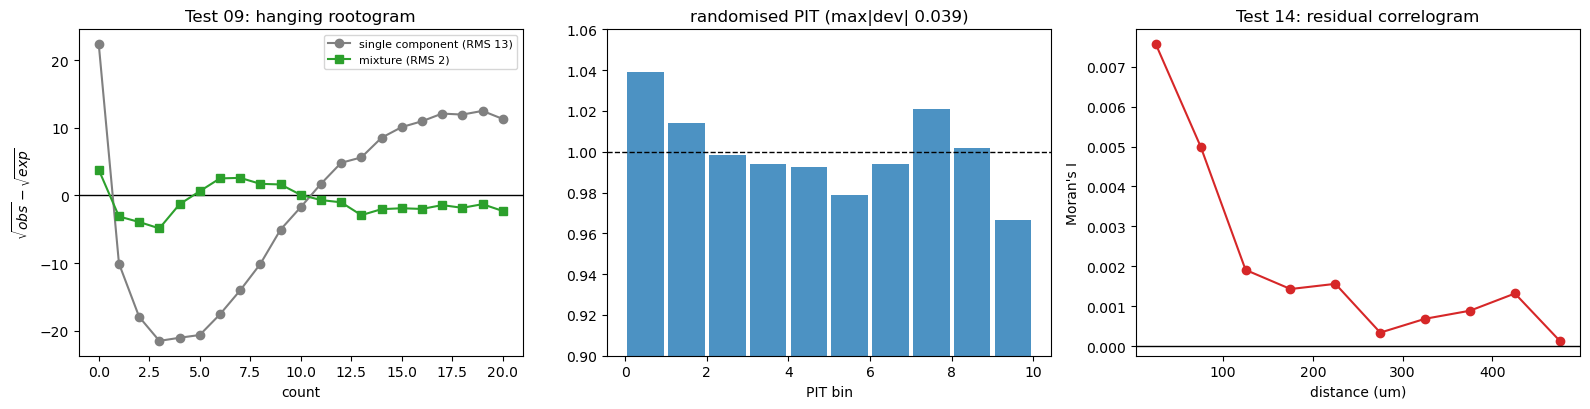

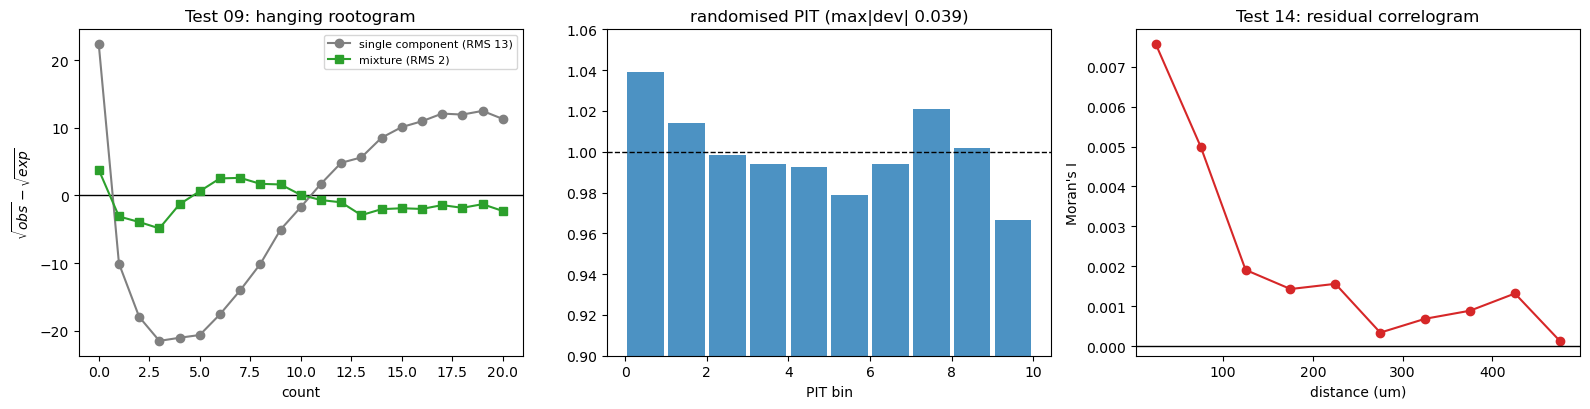

In [14]:
resid = pearson_residuals(y, P, D, spec)
xy = df[["x","y"]].to_numpy(float)
sub_i = np.random.default_rng(0).choice(len(resid), 120_000, replace=False)
mi = morans_i(resid[sub_i], coords=xy[sub_i], n_neighbors=8, permutations=99, seed=0)
cg = correlogram(resid, xy, max_dist=500.0, n_bands=10)
print(f"Test 14  Moran's I on mixture Pearson residuals = {mi['I']:.4f} (p = {mi['p_value']:.3f})")
print("         (the NB division model of the exploration notebook was ~0.0155)\n")
print("         correlogram:")
for dist, I, npair in cg[:6]:
    print(f"           {dist:>5.0f} um   I = {I:+.4f}   ({npair:,} pairs)")
print("         -> under 0.01 by 25 um: what structure remains is very local, and the")
print("            ~250 bootstrap blocks are far larger than spec 7.1's 5x requirement")

fig, ax = plt.subplots(1, 3, figsize=(16, 4.2))
ax[0].axhline(0, color="k", lw=1)
ax[0].plot(ks, disc_1, "o-", color="0.5", label=f"single component (RMS {rms(disc_1):.0f})")
ax[0].plot(ks, disc_m, "s-", color="C2", label=f"mixture (RMS {rms(disc_m):.0f})")
ax[0].set_xlabel("count"); ax[0].set_ylabel(r"$\sqrt{obs}-\sqrt{exp}$")
ax[0].set_title("Test 09: hanging rootogram"); ax[0].legend(fontsize=8)
ax[1].bar(np.arange(10)+.5, pit, width=.9, color="C0", alpha=.8)
ax[1].axhline(1, color="k", ls="--", lw=1); ax[1].set_ylim(0.9, 1.06)
ax[1].set_xlabel("PIT bin"); ax[1].set_title(f"randomised PIT (max|dev| {np.max(np.abs(pit-1)):.3f})")
ax[2].plot([x[0] for x in cg], [x[1] for x in cg], "o-", color="C3")
ax[2].axhline(0, color="k", lw=1); ax[2].set_xlabel("distance (um)"); ax[2].set_ylabel("Moran's I")
ax[2].set_title("Test 14: residual correlogram")
fig.tight_layout(); fig

### Where the model sits in space

Observed against fitted, the responsibilities, and the residuals. A bright band
of high $\hat\pi$ along one margin looked like an edge artefact; binning by
neighbour count shows $\hat\pi$ is *lowest* in the sparsest decile and peaks at
middle density, tracking the observed count throughout, so it is a real region.
That check also corrected a reading of mine: $h(\log d)$ is **hump-shaped**, not
monotone, despite its negative leading spline coefficient — a spline
coefficient's sign does not give the curve's direction.

tile-level corr(pi, w) = 0.883 -- the two maps look alike because the
spatial structure in w comes from the covariates, not from local count anomalies


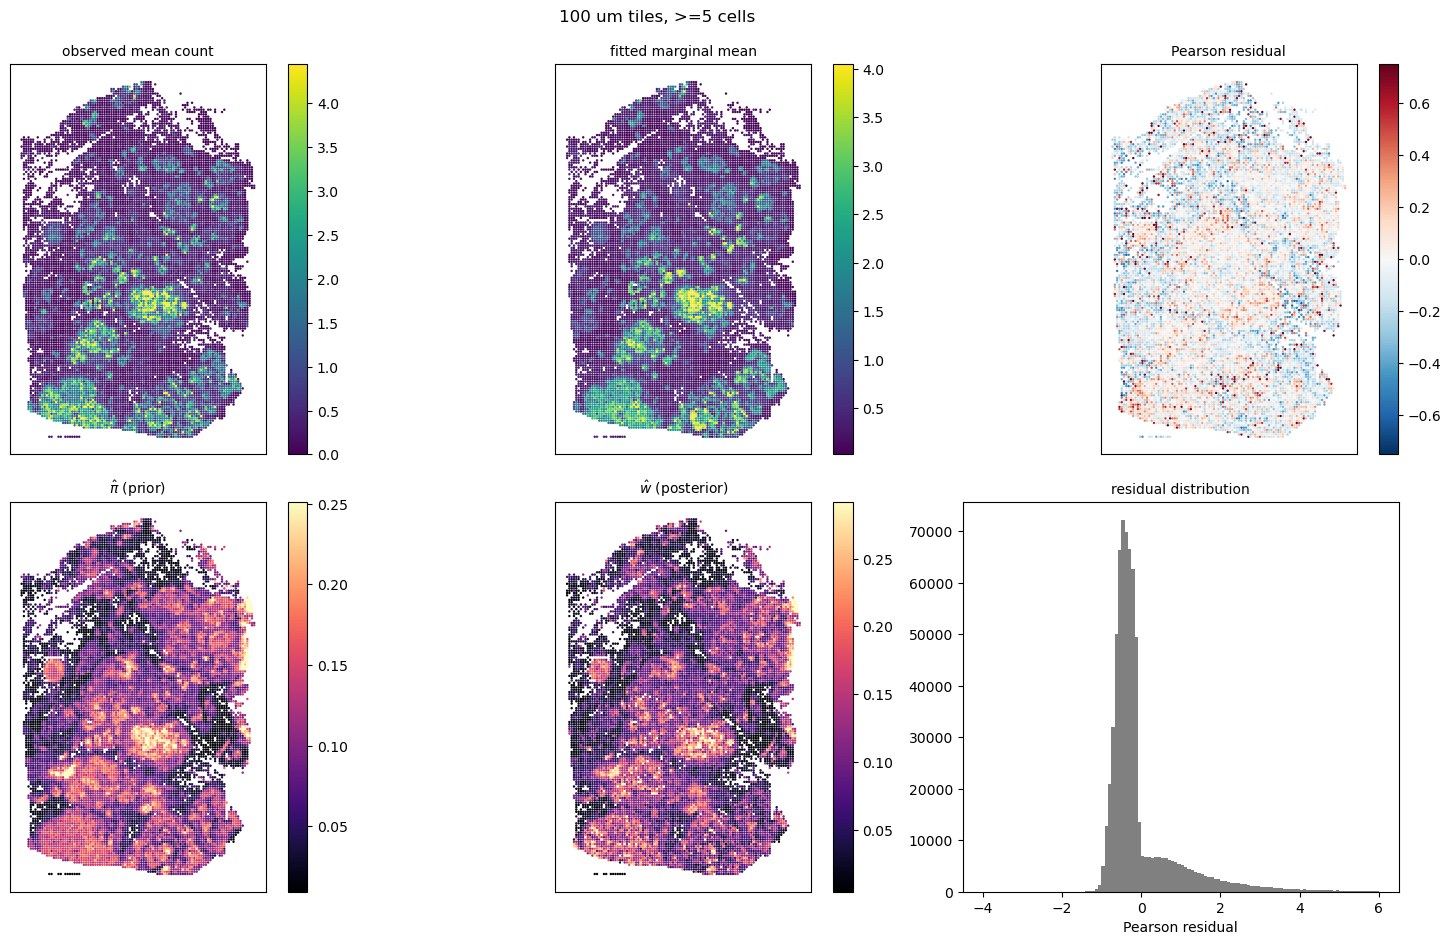

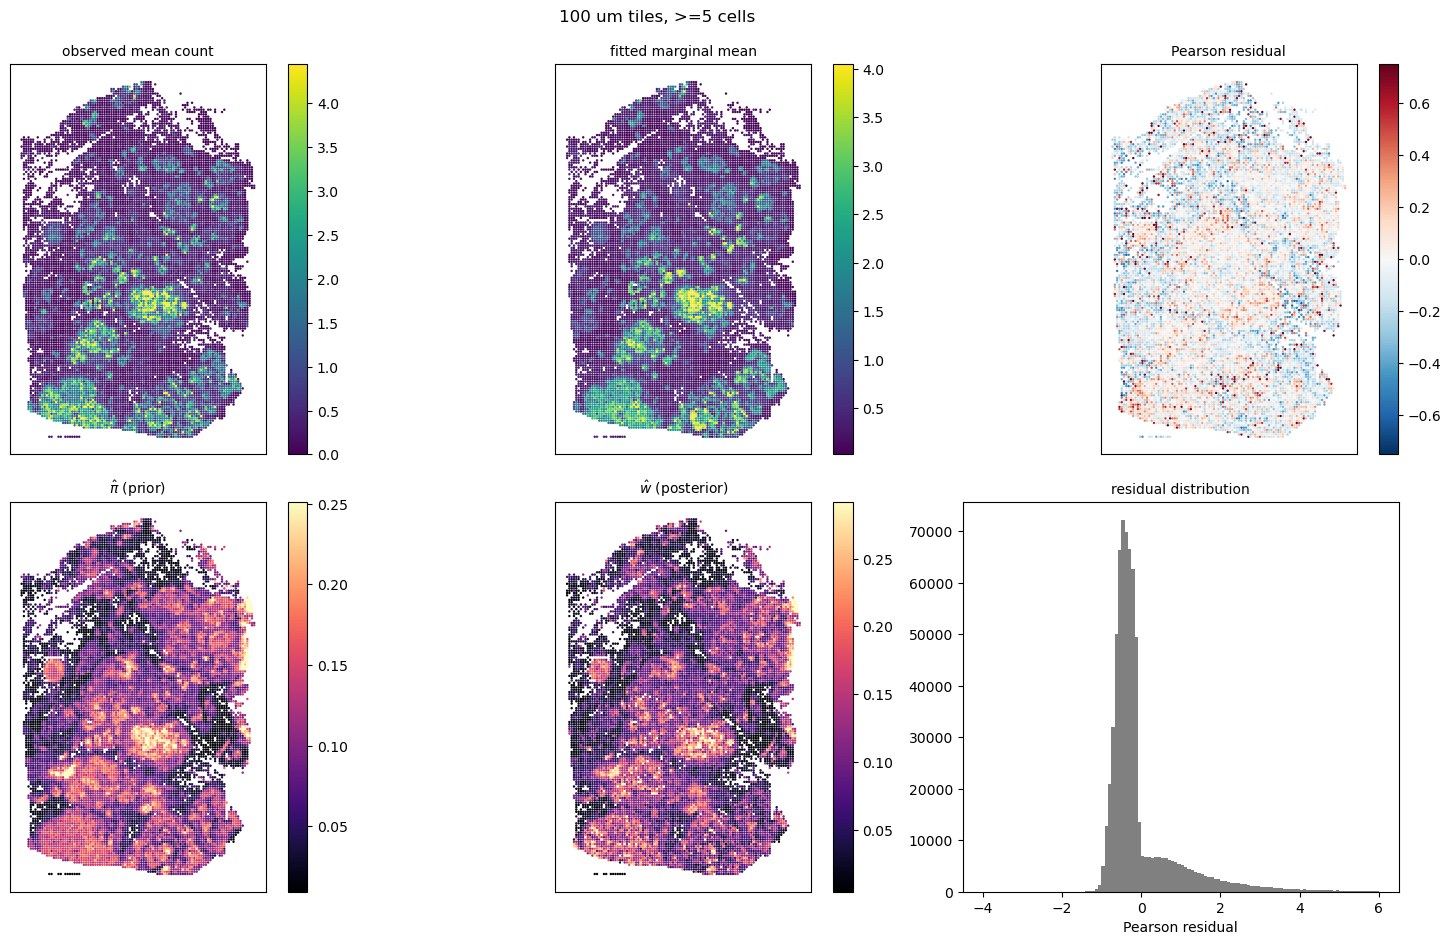

In [15]:
mu = np.asarray(marginal_mean(P, D, spec)); pi_v = np.asarray(pi_hat(P, D, spec))
TILE = 100.0
ix = ((xy[:,0]-xy[:,0].min())//TILE).astype(int); iy = ((xy[:,1]-xy[:,1].min())//TILE).astype(int)
grp = (pd.DataFrame({"ix":ix,"iy":iy,"resid":resid,"w":w,"pi":pi_v,"obs":y,"fit":mu})
       .groupby(["ix","iy"]).agg(resid=("resid","mean"), w=("w","mean"), pi=("pi","mean"),
                                 obs=("obs","mean"), fit=("fit","mean"), n=("obs","size")).reset_index())
grp = grp[grp["n"] >= 5]
def panel(ax, col, title, cmap, sym=False):
    v = grp[col].to_numpy(); lim = np.percentile(np.abs(v), 99) if sym else None
    s = ax.scatter(grp["ix"]*TILE, grp["iy"]*TILE, c=v, s=3, cmap=cmap, linewidths=0,
                   vmin=-lim if sym else np.percentile(v,1), vmax=lim if sym else np.percentile(v,99))
    ax.set_aspect("equal"); ax.set_title(title, fontsize=10); ax.set_xticks([]); ax.set_yticks([])
    plt.colorbar(s, ax=ax, fraction=0.046)
fig, ax = plt.subplots(2, 3, figsize=(16, 9.5))
panel(ax[0,0], "obs", "observed mean count", "viridis")
panel(ax[0,1], "fit", "fitted marginal mean", "viridis")
panel(ax[0,2], "resid", "Pearson residual", "RdBu_r", sym=True)
panel(ax[1,0], "pi", r"$\hat\pi$ (prior)", "magma")
panel(ax[1,1], "w", r"$\hat w$ (posterior)", "magma")
ax[1,2].hist(resid, bins=120, range=(-4,6), color="0.5")
ax[1,2].set_title("residual distribution", fontsize=10); ax[1,2].set_xlabel("Pearson residual")
fig.suptitle(f"{TILE:.0f} um tiles, >=5 cells", y=0.99); fig.tight_layout()
tile_corr = grp["pi"].corr(grp["w"])
print(f"tile-level corr(pi, w) = {tile_corr:.3f} -- the two maps look alike because the")
print("spatial structure in w comes from the covariates, not from local count anomalies")
fig

## 7. Sensitivity

Four questions: does the library-size treatment matter, does the additive
background help, does the density term contaminate the neighbourhood effect, and
does any of it depend on sample size?

In [16]:
tb = load_job("theta_bracket")
best = tb.sort_values("loglik", ascending=False).groupby("theta_free").head(1).sort_values("theta_free")
print("Configuration F (theta pinned at 1) vs V (theta free) -- spec 2.2 reports these as a")
print("BRACKET, never selecting between them: library size is simultaneously mediator")
print("and confounder, so F blocks that path and V partly unblocks it by an amount")
print("chosen by likelihood rather than causal argument (spec 9.11 forbids picking by fit).\n")
print(f"{'':<24}{'loglik':>12}{'theta':>8}{'fold':>8}{'mean w':>9}{'entropy':>9}")
for _, r in best.iterrows():
    lab = "V (theta free)" if r["theta_free"] else "F (theta fixed at 1)"
    th = r["theta"] if r["theta_free"] else 1.0
    print(f"{lab:<24}{r['loglik']:>12.1f}{th:>8.4f}{np.exp(r['e_delta']):>8.3f}"
          f"{r['mean_w']:>9.4f}{r['entropy']:>9.4f}")
f_, v_ = best[~best["theta_free"]].iloc[0], best[best["theta_free"]].iloc[0]
print(f"\nfold changes differ by {100*abs(np.exp(f_['e_delta'])-np.exp(v_['e_delta']))/np.exp(v_['e_delta']):.1f}%"
      f", cycling fractions by {100*abs(f_['mean_w']-v_['mean_w'])/v_['mean_w']:.1f}%.")
print(f"Freed, theta estimates {v_['theta']:.4f} -- essentially the 1.0 the offset assumes,")
print("so the fixed offset is a defensible simplification here.\n")
print("Contrast the NB division model of the exploration notebook, where the implied")
print("depth exponent was 0.70. The difference is N: here it excludes the blocklist, so")
print("the outcome genes sit OUTSIDE the offset. There, log_total_counts included them --")
print("a route for the outcome to inflate its own offset. That sub-proportional scaling")
print("was at least partly that artefact.")

Configuration F (theta pinned at 1) vs V (theta free) -- spec 2.2 reports these as a
BRACKET, never selecting between them: library size is simultaneously mediator
and confounder, so F blocks that path and V partly unblocks it by an amount
chosen by likelihood rather than causal argument (spec 9.11 forbids picking by fit).

                              loglik   theta    fold   mean w  entropy
F (theta fixed at 1)       -625150.8  1.0000   5.668   0.1050   0.7124
V (theta free)             -625110.4  1.0362   5.630   0.1160   0.6832

fold changes differ by 0.7%, cycling fractions by 9.5%.
Freed, theta estimates 1.0362 -- essentially the 1.0 the offset assumes,
so the fixed offset is a defensible simplification here.

Contrast the NB division model of the exploration notebook, where the implied
depth exponent was 0.70. The difference is N: here it excludes the blocklist, so
the outcome genes sit OUTSIDE the offset. There, log_total_counts included them --
a route for the outcome to infl

In [17]:
sc = load_job("stage_c")
sc = sc[sc["failed"].isna()] if "failed" in sc else sc
bc = sc.sort_values("loglik", ascending=False).iloc[0]
G = basis.density_bg_basis(df)
rho = np.exp(float(np.asarray(bc["params"]["r0"])) + G @ np.asarray(bc["params"]["g"]))
anchored = df["ctrl_count"].to_numpy(float) * (53/649)
print("Stage C -- the additive background, rejected on the spec's OWN criterion\n")
print(f"  +{bc['loglik']-pe['loglik']:.1f} log-likelihood for 3 parameters, and the estimands")
print(f"  barely move (fold {np.exp(pe['e_delta']):.3f} -> {np.exp(bc['e_delta']):.3f}). That looks like")
print("  an improvement. It is not one that can be interpreted:\n")
from tissue_dynamics.mixture.diagnostics import density_tradeoff_check
chk = density_tradeoff_check(P["h"], bc["params"]["h"], df, basis)
print(f"  spec 3.4 stability: h()'s swing across the density IQR "
      f"({chk['iqr'][0]:.0f}-{chk['iqr'][1]:.0f} cells/(100um)^2)")
print(f"    Stage B {chk['swing_stage_b']:+.4f} -> Stage C {chk['swing_stage_c']:+.4f} "
      f"log-odds, ratio {chk['ratio']:.3f}")
print(f"    trading off (sign flip, or change by more than a factor of two)? "
      f"{chk['trading_off']}\n")
print(f"  the control probes say the background should be negligible:")
print(f"    freely estimated  rho = {rho.mean():.4f} per cell = "
      f"{100*rho.mean()/df['y_count'].mean():.1f}% of the mean count")
print(f"    control-anchored  rho = {anchored.mean():.2e} per cell = "
      f"{100*anchored.mean()/df['y_count'].mean():.4f}%")
print(f"    the free background is {rho.mean()/anchored.mean():.0f}x larger than justified;")
print(f"    control counts are zero in {100*(df['ctrl_count']==0).mean():.1f}% of cells\n")
print("  -> the +475 is the background absorbing density signal from the weight, not")
print("     contamination being captured. Stage B is the specification to report.")

Stage C -- the additive background, rejected on the spec's OWN criterion

  +302.9 log-likelihood for 3 parameters, and the estimands
  barely move (fold 5.629 -> 5.683). That looks like
  an improvement. It is not one that can be interpreted:



ValueError: matmul: Input operand 1 has a mismatch in its core dimension 0, with gufunc signature (n?,k),(k,m?)->(n?,m?) (size 2 is different from 5)

In [18]:
ds = load_job("density_sensitivity")
ds["sigma1"] = [np.array(s)[0] for s in ds["sigma"]]
bd = ds.sort_values("loglik", ascending=False).groupby("df_weight").head(1).sort_values("df_weight")
c_ref = Q @ np.asarray(P["c"])
print("Test 13 -- does the density term in the weight contaminate the neighbourhood effect?\n")
print("Spec 6.13's concern: density and phi_bar are both spatially smooth on similar")
print("scales, so a flexible h() can absorb genuine neighbourhood signal. That is spatial")
print("confounding acting on the PRIMARY estimand, not on a nuisance term.\n")
print(f"{'h()':<12}{'loglik':>12}{'fold':>8}{'sigma1':>9}{'psi':>8}")
for _, r in bd.iterrows():
    lab = "dropped" if r["df_weight"] == 0 else f"df={int(r['df_weight'])}"
    print(f"{lab:<12}{r['loglik']:>12.1f}{np.exp(r['e_delta']):>8.4f}{r['sigma1']:>9.4f}{r['psi']:>8.4f}")
h0 = bd[bd["df_weight"] == 0].iloc[0]; c0 = Q @ np.asarray(h0["c"])
print("\nchange in each neighbourhood coefficient when h() is dropped entirely:\n")
print(f"{'cell type':<20}{'with h':>10}{'no h':>10}{'change':>10}")
flagged = []
for j, nm in enumerate(names):
    ch = (c0[j]-c_ref[j])/max(abs(c_ref[j]), 1e-9)
    bad = abs(ch) > 0.5 or np.sign(c0[j]) != np.sign(c_ref[j])
    if bad: flagged.append(nm)
    print(f"{nm:<20}{c_ref[j]:>+10.4f}{c0[j]:>+10.4f}{100*ch:>+9.1f}%{'  <-' if bad else ''}")
print(f"\nnbr[Cancer Epithelial] -- the headline neighbourhood effect -- moves by "
      f"{100*(c0[names.index('Cancer Epithelial')]-c_ref[names.index('Cancer Epithelial')])/abs(c_ref[names.index('Cancer Epithelial')]):+.1f}%.")
print(f"Flagged (>50% change or sign flip): {flagged}")
print("Those three have the smallest magnitudes, which is where spatial confounding bites.")
print("Report the immune neighbourhood effects with that caveat; the tumour one is safe.")

Test 13 -- does the density term in the weight contaminate the neighbourhood effect?

Spec 6.13's concern: density and phi_bar are both spatially smooth on similar
scales, so a flexible h() can absorb genuine neighbourhood signal. That is spatial
confounding acting on the PRIMARY estimand, not on a nuisance term.

h()               loglik    fold   sigma1     psi
dropped        -625220.0  5.6328   1.3010  0.7750
df=3           -625110.4  5.6295   1.3642  0.8396
df=5           -625098.0  5.6294   1.3679  0.8396

change in each neighbourhood coefficient when h() is dropped entirely:

cell type               with h      no h    change
Endothelial            -0.6476   -0.9201    -42.1%
CAFs                   -0.4859   -0.8796    -81.0%  <-
PVL                    +0.1390   +0.0824    -40.7%
B-cells                -0.5406   -0.2743    +49.2%
T-cells                +0.1723   +0.8371   +385.7%  <-
Myeloid                -0.1105   -0.1437    -30.1%
Normal Epithelial      -0.5858   -0.8618    -4

In [19]:
ss = load_job("subsample_stability")
ss["sigma1"] = [np.array(s)[0] for s in ss["sigma"]]; ss["fold"] = np.exp(ss["e_delta"])
ci_f = np.exp(np.percentile(boot["e_delta"], [2.5, 97.5]))
ci_w = np.percentile(boot["mean_w"], [2.5, 97.5])
print("Test 10 -- subsample stability\n")
print(f"{'n':<10}{'restarts':>9}{'agreement':>11}{'sigma1':>9}{'mean pi':>10}{'fold':>9}")
for n_ in (50000, 200000, 0):
    s = ss[ss["n_cells"] == n_]; l_ = s["loglik"].to_numpy(); b_ = s.loc[s["loglik"].idxmax()]
    lab = "full" if n_ == 0 else f"{n_:,}"
    print(f"{lab:<10}{len(s):>9}{100*np.mean(l_>l_.max()-1e-6):>10.0f}%"
          f"{b_['sigma1']:>9.4f}{b_['mean_w']:>10.4f}{b_['fold']:>9.4f}")
print(f"\nfull-sample CIs: fold [{ci_f[0]:.4f}, {ci_f[1]:.4f}], mean pi [{ci_w[0]:.4f}, {ci_w[1]:.4f}]")
print("\nThe fold change is stable at every size. mean(pi) matches the full sample exactly")
print("at 200,000 and is inflated at 50,000; sigma_1 decreases monotonically (1.90 / 1.46 /")
print("1.36), the signature of a variance-dominated estimate at small n. This model wants")
print("on the order of 200,000 cells.")
print("\nBoth subsamples are severely multimodal (1 of 20 restarts finds the best optimum)")
print("against 95% agreement at the full sample, so spec 4.4's best-of-N caveat applies to")
print("any subsample fit and not to the full-sample one being reported.")

IndexError: index -1 is out of bounds for axis 0 with size 0

## 8. Limitations

- **One section, no biological replicate.** Every interval here is a *within*-section
  bootstrap: it bounds how much the answer depends on which parts of this tumour
  were sampled, not how much it would vary between tumours.
- **Test 07's fold criterion fails.** On class-free data the model still reports a
  ~1.93× fold change. The three arguments above bound it, but the caveat should
  travel with the number.
- **Test 09 is not uniform.** Cancer Epithelial improves 77% and Plasmablasts 65%,
  but T-cells worsen 46% and B-cells 69%.
- **Three immune neighbourhood coefficients are density-sensitive** (Test 13).
- **The proportional-rates restriction is untested.** Spec 2.2 makes it
  load-bearing for identifiability; relaxing it needs a second $\theta$ in the
  model, which is a modelling change rather than a config flag. It is the one
  assumption in the specification that has not been challenged.
- **The oxygen field failed its HIF-target check**, so $\psi$ reads as vessel
  proximity / perfusion, not hypoxia. Its uncertainty is not propagated into
  these intervals.
- **$\hat\pi$ is a snapshot prevalence, not a rate.** Converting to a division
  rate needs $\lambda_i \approx \hat\pi_i / T_{S/G2M}$ with the S/G2M duration
  taken from literature — a downstream assumption, not something this fit
  provides.

---

## 9. The density response, per cell phenotype

The mixing weight carries local density through a spline $h(\log d)$. Two
questions decide how that term should be built, and both were settled by fitting
the alternatives side by side (`weight_variants`, 60 fits, 20 restarts each).

**Does the density response need to differ by cell type?** Adjusted for detection
and neighbourhood composition, log density *raises* the odds of cycling for
Myeloid, Endothelial, Normal Epithelial, PVL and CAFs but *lowers* them for
Cancer Epithelial. A single shared curve averages those into one monotonically
increasing function and the tumour's response disappears.

**Does it need to differ in shape, or only in level?** A per-type *tilt* shifts
each curve up or down but keeps one shape for all. Contact inhibition — rising
with density, then turning down once crowded — is a *shape*, so a tilt cannot
represent it. Nor can a natural cubic spline bend in its upper tail without an
interior knot there, which is why the knots are placed explicitly at the
25th/50th/75th/90th percentiles rather than left to `df`.

In [20]:
wv = load_job("weight_variants")
wv["sigma1"] = [x[0] if isinstance(x, list) and x else np.nan for x in wv["sigma"]]
best_v = {v: wv[wv["variant"] == v].sort_values("loglik", ascending=False).iloc[0]
          for v in wv["variant"].unique()}
npar = {"knots_only": 65, "linear_interaction": 73, "spline_interaction": 105}
order = ["knots_only", "linear_interaction", "spline_interaction"]
ref = best_v["knots_only"]["loglik"]
print(f"{'variant':<20}{'params':>8}{'loglik':>13}{'vs knots_only':>15}{'per param':>11}"
      f"{'fold':>9}{'mean pi':>9}{'sigma1':>9}")
for v in order:
    r = best_v[v]; gain = r["loglik"] - ref; dp = npar[v] - npar["knots_only"]
    print(f"{v:<20}{npar[v]:>8}{r['loglik']:>13.1f}{gain:>15.1f}"
          + (f"{gain/dp:>11.1f}" if dp else f"{'-':>11}")
          + f"{np.exp(r['e_delta']):>9.4f}{r['mean_w']:>9.4f}{r['sigma1']:>9.4f}")
kl = best_v["linear_interaction"]["loglik"] - ref
sl = best_v["spline_interaction"]["loglik"] - best_v["linear_interaction"]["loglik"]
print(f"\nmarginal gains, against the ~0.5 per parameter that pure overfitting yields:")
print(f"  per-type TILT   (+8 params)  {kl:+8.1f} = {kl/8:5.1f} per param")
print(f"  per-type CURVE (+32 params)  {sl:+8.1f} = {sl/32:5.1f} per param")
print(f"\nEvery headline estimand is unchanged across the three (fold to 3 decimals,")
print(f"mean pi within 1.4%), so this choice does not move the reported results --")
print(f"it changes what the model is able to say about density.")

variant               params       loglik  vs knots_only  per param     fold  mean pi   sigma1
knots_only                65    -625123.6            0.0          -   5.6297   0.1159   1.3102
linear_interaction        73    -625016.4          107.2       13.4   5.6279   0.1164   1.3051
spline_interaction       105    -624938.1          185.5        4.6   5.6294   0.1148   1.3805

marginal gains, against the ~0.5 per parameter that pure overfitting yields:
  per-type TILT   (+8 params)    +107.2 =  13.4 per param
  per-type CURVE (+32 params)     +78.3 =   2.4 per param

Every headline estimand is unchanged across the three (fold to 3 decimals,
mean pi within 1.4%), so this choice does not move the reported results --
it changes what the model is able to say about density.


### The fitted curves

Left: the single curve every cell type is forced to share. Right: one curve per
phenotype. Dotted lines mark the knots.

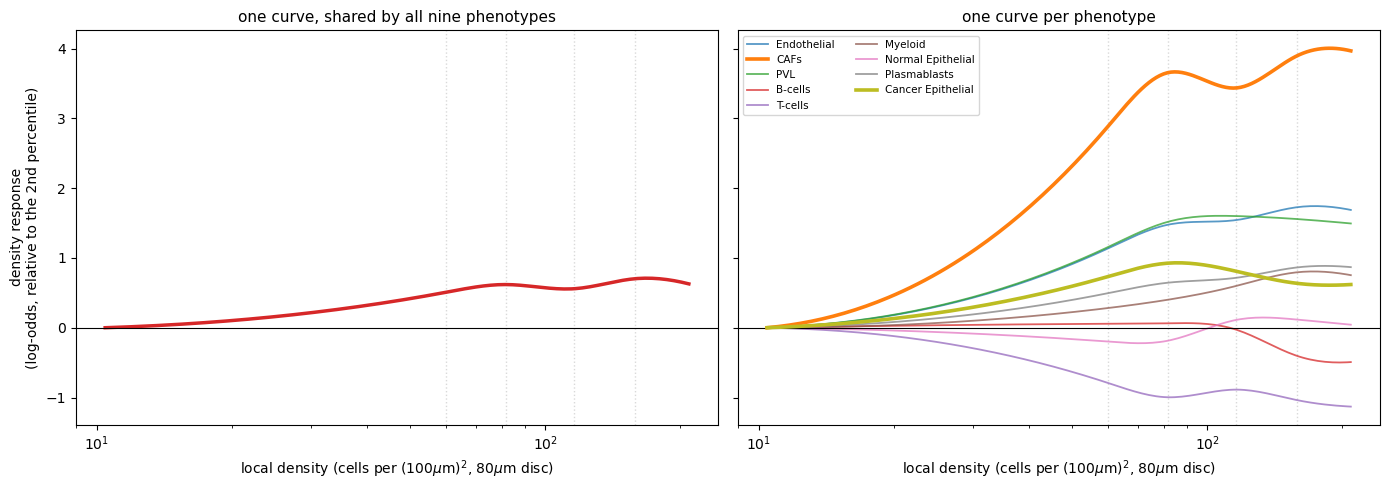

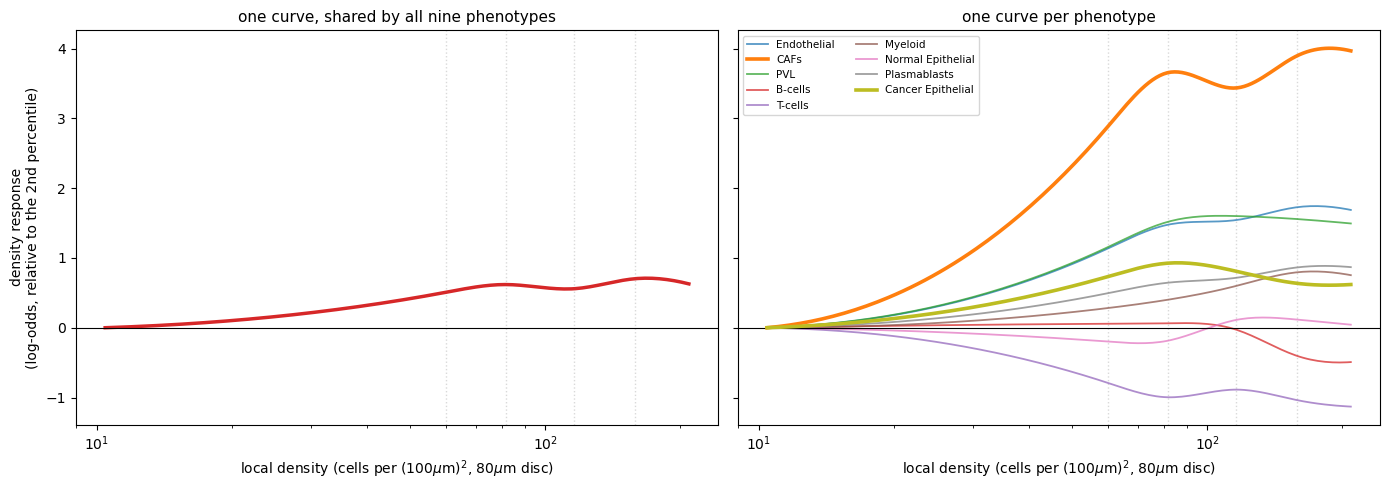

In [21]:
QK = Q @ np.asarray(best_v["spline_interaction"]["params"]["K"])
h_sp = np.asarray(best_v["spline_interaction"]["params"]["h"])
h_ko = np.asarray(best_v["knots_only"]["params"]["h"])
dens = df["density"].to_numpy(float)
grid = np.exp(np.linspace(np.log(np.percentile(dens, 2)), np.log(np.percentile(dens, 98)), 160))
Hg = basis.density_weight_basis(pd.DataFrame({"density": grid}))
knots = np.exp(basis.density_weight_spline.knots)

fig, ax = plt.subplots(1, 2, figsize=(14, 5), sharey=True)
c0 = Hg @ h_ko
ax[0].plot(grid, c0 - c0[0], color="C3", lw=2.5)
ax[0].set_title("one curve, shared by all nine phenotypes", fontsize=11)
cmap = plt.get_cmap("tab10")
for j, nm in enumerate(names):
    cur = Hg @ h_sp + Hg @ QK[j]; cur = cur - cur[0]
    hi = nm in ("Cancer Epithelial", "CAFs")
    ax[1].plot(grid, cur, color=cmap(j % 10), lw=2.6 if hi else 1.3,
               alpha=1.0 if hi else 0.75, label=nm, zorder=3 if hi else 2)
ax[1].set_title("one curve per phenotype", fontsize=11); ax[1].legend(fontsize=7.5, ncol=2)
for a_ in ax:
    a_.axhline(0, color="k", lw=.8); a_.set_xscale("log")
    for k_ in knots: a_.axvline(k_, color="0.85", ls=":", lw=1, zorder=0)
    a_.set_xlabel(r"local density (cells per (100$\mu$m)$^2$, 80$\mu$m disc)")
ax[0].set_ylabel("density response\n(log-odds, relative to the 2nd percentile)")
fig.tight_layout(); fig

### Per-phenotype detail

Each panel shows one phenotype's density response against the shared curve, with
the observed density distribution beneath. The number is the change in log-odds
from the peak to the 98th percentile — **negative means the response turns down
once crowded, which is contact inhibition**.

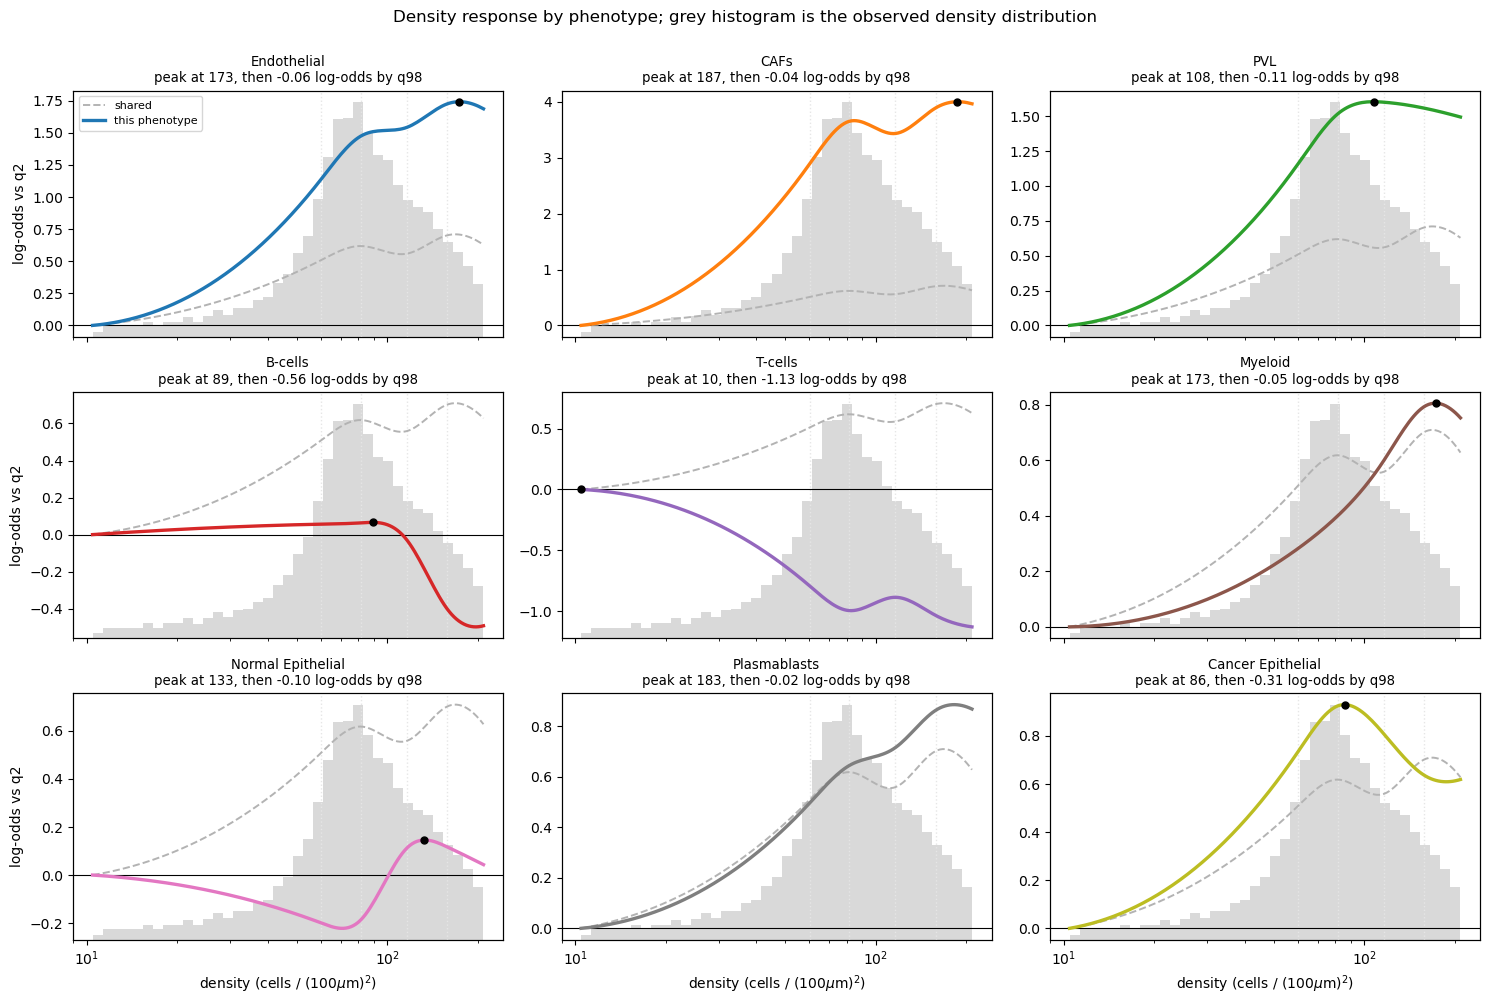

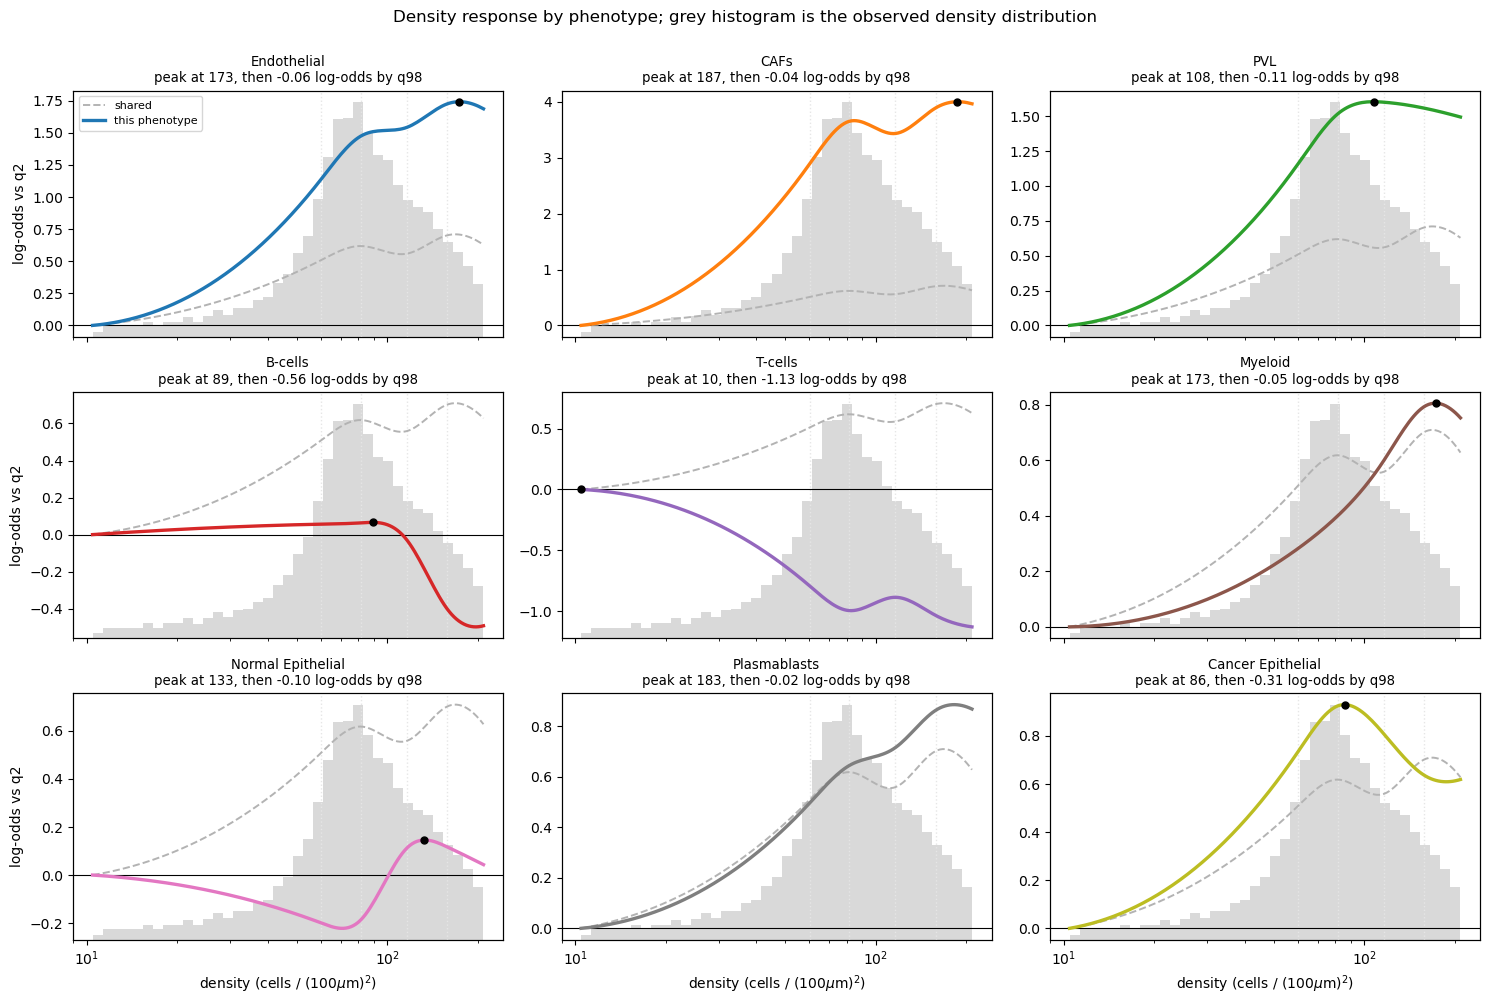

In [22]:
fig, axes = plt.subplots(3, 3, figsize=(15, 10), sharex=True)
shared = Hg @ h_ko; shared = shared - shared[0]
for ax_, (j, nm) in zip(axes.ravel(), enumerate(names)):
    cur = Hg @ h_sp + Hg @ QK[j]; cur = cur - cur[0]
    pk = int(np.argmax(cur)); drop = cur[pk] - cur[-1]
    ax_.axhline(0, color="k", lw=.8)
    ax_.plot(grid, shared, color="0.7", lw=1.4, ls="--", label="shared")
    ax_.plot(grid, cur, color=cmap(j % 10), lw=2.4, label="this phenotype")
    if drop > 0.02:
        ax_.plot(grid[pk], cur[pk], "o", color="k", ms=5, zorder=5)
    ax_.set_xscale("log")
    for k_ in knots: ax_.axvline(k_, color="0.9", ls=":", lw=1, zorder=0)
    tw = ax_.twinx(); tw.hist(dens, bins=np.geomspace(grid[0], grid[-1], 40),
                              color="0.85", zorder=0); tw.set_yticks([]); tw.set_zorder(0)
    ax_.set_zorder(1); ax_.patch.set_visible(False)
    ax_.set_title(f"{nm}\npeak at {grid[pk]:.0f}, then {-drop:+.2f} log-odds by q98",
                  fontsize=9.5)
axes[0, 0].legend(fontsize=8)
for ax_ in axes[-1]:
    ax_.set_xlabel(r"density (cells / (100$\mu$m)$^2$)")
for ax_ in axes[:, 0]:
    ax_.set_ylabel("log-odds vs q2")
fig.suptitle("Density response by phenotype; grey histogram is the observed density distribution", y=1.0)
fig.tight_layout(); fig

In [23]:
print("net density response by phenotype, log-odds relative to the 10th percentile\n")
qq = [10, 25, 50, 75, 90, 95]
Hq = basis.density_weight_basis(pd.DataFrame({"density": np.percentile(dens, qq)}))
print(f"{'phenotype':<20}" + "".join(f"{'q'+str(q):>9}" for q in qq) + "   shape")
for j, nm in enumerate(names):
    cur = Hq @ h_sp + Hq @ QK[j]; rel = cur - cur[0]
    shape = ("rises then falls" if rel[-1] < rel.max() - 0.02
             else ("falls" if rel[-1] < -0.02 else "rises"))
    print(f"{nm:<20}" + "".join(f"{v:>+9.3f}" for v in rel) + f"   {shape}")
c0q = Hq @ h_ko
print(f"\n{'(shared curve)':<20}" + "".join(f"{v:>+9.3f}" for v in c0q - c0q[0]))
print("\nCancer Epithelial rises to a peak near the median density and then falls --")
print("the shared curve is monotonically increasing and hides it entirely.")
print("\nCAFs reach +4 log-odds (a 55-fold odds ratio) across the range, six times the")
print("shared curve's whole span. That magnitude has NOT yet been checked against a")
print("bootstrap and should be treated as provisional.")

net density response by phenotype, log-odds relative to the 10th percentile

phenotype                 q10      q25      q50      q75      q90      q95   shape
Endothelial            +0.000   +0.577   +0.914   +0.981   +1.165   +1.176   rises
CAFs                   +0.000   +1.458   +2.221   +2.002   +2.460   +2.570   rises
PVL                    +0.000   +0.585   +0.943   +1.027   +0.984   +0.952   rises then falls
B-cells                +0.000   +0.011   +0.018   -0.073   -0.447   -0.535   rises then falls
T-cells                +0.000   -0.407   -0.611   -0.501   -0.650   -0.715   rises then falls
Myeloid                +0.000   +0.149   +0.267   +0.465   +0.661   +0.667   rises
Normal Epithelial      +0.000   -0.093   -0.081   +0.217   +0.223   +0.185   rises then falls
Plasmablasts           +0.000   +0.248   +0.397   +0.467   +0.616   +0.638   rises
Cancer Epithelial      +0.000   +0.358   +0.548   +0.433   +0.260   +0.233   rises then falls

(shared curve)         +0.000   +0.23